# Daily weather observations from KNMI: Open Data API vs EDR API

This notebook shows how to get data from the
[KNMI Data Platform](https://dataplatform.knmi.nl/) with the `knmidata`
Python package, using the dataset
[**daily-in-situ-meteorological-observations**](https://dataplatform.knmi.nl/dataset/access/daily-in-situ-meteorological-observations-1-0)
(daily observations from the Dutch automatic weather stations).

We fetch the same dataset through **both** APIs and compare:

1. **Open Data API** — download whole files (NetCDF) and open them as one
   `xarray.Dataset`.
2. **EDR API** — run spatio-temporal *queries* (location / area), parse the
   response into an `xarray.Dataset`, and plot the time series of
   precipitation (RH), temperature (TG) and evaporation (EV24) at De Bilt.


## How KNMI data is organized

- The **KNMI Data Platform** (`dataplatform.knmi.nl`) is the data catalog.
  Everything in it is a **dataset** with a unique *name* and *version*
  (e.g. `daily-in-situ-meteorological-observations`, version `1.0`). The
  version matters: the API paths contain both.
- Datasets come in two flavours:
  - **in-situ observations**: point measurements at automatic weather
    stations (AWS), e.g. temperature, wind, precipitation per station;
  - **gridded products**: radar composites, HARMONIE model output, satellite
    imagery — regularly spaced grids.
- Each dataset is exposed through one or two APIs (see the "Access" tab on
  the dataset page):
  - the **Open Data API** (`/open-data/v1`): file-based — you list files and
    download them (via temporary presigned S3 URLs);
  - the **EDR API** (`/edr/v1`): an OGC standard for spatio-temporal
    *queries* — you ask for a point, area, or cube and get back a structured
    payload (CoverageJSON), no files involved.
- Times are **UTC** everywhere. KNMI file names embed the observation time
  (e.g. `..._20260601.nc` = 2026-06-01).
- This dataset holds **daily** values per station. The variable codes are the
  classic KNMI "etmaalwaarden" codes: **TG** = daily mean temperature (°C),
  **RH** = daily precipitation sum (mm), **EV24** = Makkink reference
  evaporation (mm), plus TN/TX (min/max temperature), FG (mean wind), etc.

## The two APIs at a glance

| | Open Data API | EDR API |
|---|---|---|
| Base URL | `api.dataplatform.knmi.nl/open-data/v1` | `api.dataplatform.knmi.nl/edr/v1` |
| Model | list *files* in a dataset, get a presigned download URL per file | query a *collection* by location/time/parameters |
| Typical use | bulk download of whole files / long history | targeted extracts: one station, one period, a few parameters |
| You get | NetCDF/HDF5 files on disk → `xarray` | CoverageJSON/GeoJSON → parsed to `xarray.Dataset` in memory |
| Granularity | whole files (all stations/variables in the file) | exactly the queried subset |
| Auth | anonymous key possible (shared, rate-limited) | registered key required (dedicated quota) |

Rule of thumb: **use EDR when you know what you want** (a station, a bbox, a
time range, a few variables); **use Open Data when you want everything**
(whole files, full archives, model/radar grids).

## Authentication

Every request needs an API key in the `Authorization` header (raw key, no
`Bearer` prefix). Request a free registered key at
[developer.dataplatform.knmi.nl](https://developer.dataplatform.knmi.nl/).

`knmidata` resolves keys in this order — explicit argument first, then
environment variables:

| API | Argument | Environment variables |
|---|---|---|
| Open Data | `api_key=` | `KNMI_OPENDATA_API_KEY` (+`_FILE`), then the public anonymous key |
| EDR | `edr_key=` | `KNMI_EDR_API_KEY` (+`_FILE`) |

Note: **Open Data and EDR keys are not interchangeable**, and the EDR API
has no anonymous key. The anonymous Open Data key is published on the docs
page and scraped automatically by `knmidata`, but it shares one rate limit
across all anonymous users.

### Keeping the key out of shared notebooks

**Never paste the key into a notebook cell** — anyone who can view the
notebook (or its saved outputs, git history, screenshots) can see it. Safe
patterns, in order of preference:

1. **`.env` file (gitignored) + python-dotenv.** Create a `.env` file (see the README Authentication section)
   to `.env`, fill in your keys, `chmod 600 .env`. `.env` is in
   `.gitignore`, so it is never committed. In the notebook, only load it:
   `load_dotenv()` — the key itself never appears in the notebook.
   Install with `pip install knmidata[dotenv]`.
2. **Shell environment variables**: `export KNMI_OPENDATA_API_KEY=...` /
   `export KNMI_EDR_API_KEY=...` in your profile or before launching Jupyter.
3. **Key file**: set `KNMI_OPENDATA_API_KEY_FILE=/path/to/key.txt` (chmod 600)
   instead of the key itself; `knmidata` reads the file for you.
4. **GitHub Actions**: store the key as a repository *secret* and pass it
   to the workflow step as an env var (see `.github/workflows/documentation.yml`,
   which executes this notebook in CI) — GitHub masks secret values in logs.

Additional hygiene: `knmidata` never prints or logs the key (check with
`bool(os.environ.get("KNMI_OPENDATA_API_KEY"))`, not by printing it); when sharing an
executed `.ipynb`, strip outputs first (the repo's pre-commit already runs
`nbstripout`); if a key ever does leak, revoke/rotate it in the
[developer portal](https://developer.dataplatform.knmi.nl/).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import knmidata

# The dataset from the KNMI Data Platform page linked above.
DATASET_NAME = "daily-in-situ-meteorological-observations"
DATASET_VERSION = "1.0"
COLLECTION = "daily-in-situ-meteorological-observations"  # EDR collection id

# The variables we plot below (classic KNMI daily "etmaalwaarden" codes):
# RH = daily precipitation sum (mm), TG = daily mean temperature (degC),
# EV24 = Makkink reference evaporation (mm).
PARAMETERS = ["RH", "TG", "EV24"]

# De Bilt (KNMI's own station, WSI 0-20000-0-06260), as (lon, lat) — the
# station's grid point in the EDR responses.
STATION_COORDS = (5.18, 52.10)
# Bounding box over the Netherlands: (minx, miny, maxx, maxy).
NL_BBOX = (3.0, 50.5, 7.5, 53.7)

# Time arguments accept str, pd.Timestamp, datetime, or date; naive = UTC.
# One week of daily values (change to e.g. a month for a longer time series).
START = pd.Timestamp("2026-06-01")
END = pd.Timestamp("2026-06-08")

# Downloaded Open Data files are kept here (omit cache_dir to load into
# memory only and delete the files afterwards).
CACHE_DIR = Path("data")

knmidata.show_versions()

Versions:
  python: 3.13.18
  knmidata: 2.0.0
  httpx: 0.28.1
  xarray: 2026.9.0
  h5netcdf: 1.8.2


## Setup: create a client

`KNMIClient` is the synchronous client (runs everything on a background
event loop, so it also works inside Jupyter). For async code use
`AsyncKNMIClient` instead. Without keys, Open Data falls back to the
anonymous key; the EDR part below checks whether a key is available and
skips gracefully otherwise.

In [2]:
import os

# Load keys from the gitignored .env file (see the README Authentication section).
# The key itself never appears in this notebook. On GitHub Actions, skip the
# .env file: store the key as a repository *secret* and expose it to the
# workflow as an env var (see .github/workflows/documentation.yml) — GitHub
# masks secret values in logs.
try:
    from dotenv import load_dotenv

    load_dotenv(".env")
except ImportError:
    pass  # alternative: export KNMI_OPENDATA_API_KEY / KNMI_EDR_API_KEY in your shell

# Presence check only — never print the key itself.
print("KNMI_OPENDATA_API_KEY set:", bool(os.environ.get("KNMI_OPENDATA_API_KEY")))
print("KNMI_EDR_API_KEY set:", bool(os.environ.get("KNMI_EDR_API_KEY")))

try:
    client = knmidata.KNMIClient(
        api_key=os.environ.get("KNMI_OPENDATA_API_KEY") or None,
        edr_key=os.environ.get("KNMI_EDR_API_KEY") or None,
    )  # keys are resolved from the environment
    client_ok = True
except knmidata.KNMIAuthError as exc:
    client = None
    client_ok = False
    print(f"Could not create a client (no usable key?): {exc}")

KNMI_OPENDATA_API_KEY set: True
KNMI_EDR_API_KEY set: True


## 1. Open Data API — list and download whole files

The Open Data API is **file-based**:

1. `GET /datasets/{name}/versions/{version}/files` lists the files, with
   cursor pagination (`maxKeys` up to 1000 + `nextPageToken`).
2. Time filtering uses `begin`/`end`, but note: they are compared against
   the `orderBy` attribute. `knmidata` therefore sends
   `orderBy=lastModified` automatically when you pass `start_time`/`end_time`
   (with the default `orderBy=filename`, `begin`/`end` would be compared as
   *filename strings* instead of timestamps).
3. `GET .../files/{filename}/url` returns a short-lived **presigned S3 URL**.
4. The file is streamed to disk (atomic `.part` → rename, size-checked), and
   `get_dataset` assembles the files into one `xarray.Dataset`
   (`combine_by_coords` over the time dimension).

In [3]:
files = client.opendata.list_files(
    DATASET_NAME,
    DATASET_VERSION,
    start_time=START,
    end_time=END,
)
print(f"{len(files)} files between {START} and {END}: {files}")

7 files between 2026-06-01 00:00:00 and 2026-06-08 00:00:00: ['daily-observations-20260531.nc', 'daily-observations-20260601.nc', 'daily-observations-20260602.nc', 'daily-observations-20260603.nc', 'daily-observations-20260604.nc', 'daily-observations-20260605.nc', 'daily-observations-20260606.nc']


Now download just the first two files of that period and open them as a
single dataset. Each **daily** file contains all stations for that day, so
even `max_files=2` already gives you a 2-day, all-stations slice.

`start_time`/`end_time` are normalized to UTC ISO-8601 (`...Z`) before being
sent — passing `pd.Timestamp` objects is fine.

In [4]:
ds = client.opendata.get_dataset(
    DATASET_NAME,
    DATASET_VERSION,
    start_time=START,
    end_time=END,
    cache_dir=CACHE_DIR,
)

print(f"\nDownloaded files are cached in: {CACHE_DIR.resolve()}")
print("\nCombined dataset:")
print(ds)
print("\nVariables in the dataset:", list(ds.data_vars))

/home/runner/work/KNMI_Data_Platform/KNMI_Data_Platform/.tox/notebooks/lib/python3.13/site-packages/knmidata/opendata/parsers.py:52: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return cast("xr.Dataset", xr.combine_by_coords(datasets))



Downloaded files are cached in: /home/runner/work/KNMI_Data_Platform/KNMI_Data_Platform/data

Combined dataset:
<xarray.Dataset> Size: 267kB
Dimensions:      (time: 7, station: 67)
Coordinates:
  * time         (time) datetime64[ns] 56B 2026-06-01 2026-06-02 ... 2026-06-07
  * station      (station) <U15 4kB '0-20000-0-06201' ... '0-20000-0-78990'
Data variables: (12/53)
    wsi          (time, station) <U15 28kB '0-20000-0-06201' ... '0-20000-0-7...
    stationname  (time, station) <U25 47kB 'D15-FA-1' ... 'Bonaire Airport'
    lat          (time, station) float64 4kB 54.33 52.36 53.27 ... 17.5 12.13
    lon          (time, station) float64 4kB 2.936 3.342 3.628 ... -62.98 -68.28
    height       (time, station) float64 4kB 42.7 41.84 41.8 ... 31.0 36.02 2.11
    DDFHX        (station, time) float64 4kB 150.0 190.0 180.0 ... 110.0 100.0
    ...           ...
    W1           (station, time) float64 4kB 0.0 0.0 1.0 0.0 ... 0.0 0.0 0.0 0.0
    W2           (station, time) float64 4kB 2

## 2. EDR API — query instead of download

The EDR API (OGC Environmental Data Retrieval standard) exposes datasets as
**collections**:

- `GET /collections` / `GET /collections/{id}` — what's available: which
  parameters (variables, under the `parameter-names` key), which output
  formats, the spatial/temporal extent.
- `GET /collections/{id}/locations` — the measurement locations (GeoJSON).
- Data queries, with `start_time`/`end_time` (RFC 3339 interval),
  `parameter-name` and `f` (CoverageJSON/GeoJSON) query parameters.

Instead of files, you get a structured JSON payload describing exactly the
queried cube of data, which `knmidata` parses into an `xarray.Dataset`
in memory. For station collections there are **three ways** to pick the
station(s) — shown below:

| Method | Call | When to use |
|---|---|---|
| by station id | `client.edr.get_location(COLLECTION, location_id, ...)` | you know the station id (WSI) |
| nearest to a point | `client.edr.nearest_location(COLLECTION, coords)` → id, then `get_location`; or `client.edr.get_position(..., coords=...)` (server-side, tolerance-limited) | you have coordinates |
| area / bbox | `client.edr.get_area(COLLECTION, bbox=...)` | you want all stations in a region |

In [5]:
collections = client.edr.collections()

print(
    f"Available EDR collections: {[c['id'] for c in collections.get('collections', [])]}"
)

Available EDR collections: ['Tg1', 'Tn1', 'Tx1', 'Rd1', 'EV24', 'wins50', '10-minute-in-situ-meteorological-observations', 'hourly-in-situ-meteorological-observations', 'hourly-in-situ-meteorological-observations-validated', 'daily-in-situ-meteorological-observations', 'daily-in-situ-meteorological-observations-validated', 'monthly-in-situ-meteorological-observations-validated', 'annual-in-situ-meteorological-observations-validated']


In [6]:
# Collection metadata: description, extent, and the available parameters.
# (The wire key is "parameter-names"; fall back to other spellings.)
meta = client.edr.collection(COLLECTION)
params_meta = (
    meta.get("parameter-names")
    or meta.get("parameter_names")
    or meta.get("parameters")
    or {}
)
print(
    f"\nCollection '{COLLECTION}': {len(params_meta)} parameters, e.g. "
    + ", ".join(list(params_meta)[:8])
)
# Check that the variables we want are actually in this collection.
missing = [p for p in PARAMETERS if p not in params_meta]
print(f"Requested {PARAMETERS}; missing from collection: {missing or 'none'}")


Collection 'daily-in-situ-meteorological-observations': 47 parameters, e.g. DDFHX, DDVEC, DR, EEG, EV24, FG, FHN, FHNH
Requested ['RH', 'TG', 'EV24']; missing from collection: none


### Method 1: by station id — `get_location`

`/collections/{id}/locations/{location_id}` with `start_time`/`end_time` and
`parameter-name` returns one station's time series (a CoverageCollection with
a single coverage). We ask for **RH** (precipitation sum), **TG** (mean
temperature) and **EV24** (Makkink evaporation).

In [7]:
de_bilt_id = "0-20000-0-06260"  # WSI of De Bilt — the EDR location id (the short WMO id '06260' is not accepted)
ts = client.edr.get_location(
    COLLECTION,
    de_bilt_id,
    start_time=START,
    end_time=END,
    parameters=PARAMETERS,
)
print(f"Daily time series at station {de_bilt_id}:")
print(ts)

Daily time series at station 0-20000-0-06260:
<xarray.Dataset> Size: 328B
Dimensions:  (station: 1, time: 8)
Coordinates:
  * station  (station) <U14 56B '5.1797,52.0989'
    lon      (station) float64 8B 5.18
    lat      (station) float64 8B 52.1
  * time     (time) datetime64[us, UTC] 64B 2026-06-01 00:00:00+00:00 ... 202...
Data variables:
    EV24     (station, time) float64 64B 3.9 3.8 1.5 2.5 2.6 3.0 2.4 2.2
    RH       (station, time) float64 64B 0.0 0.0 11.7 3.9 0.0 12.4 0.5 1.1
    TG       (station, time) float64 64B 19.1 18.7 16.5 16.0 15.8 16.0 15.7 15.4


### Plot the EDR time series

The parsed dataset is a plain `xarray.Dataset`, so plotting is one line per
variable (needs `matplotlib`, included in the `notebooks` extra). If the
Open Data download above succeeded, its values for the same station are
overlaid for comparison.

Text(0.5, 0.98, 'Daily values at De Bilt, 2026-06-01 to 2026-06-08')

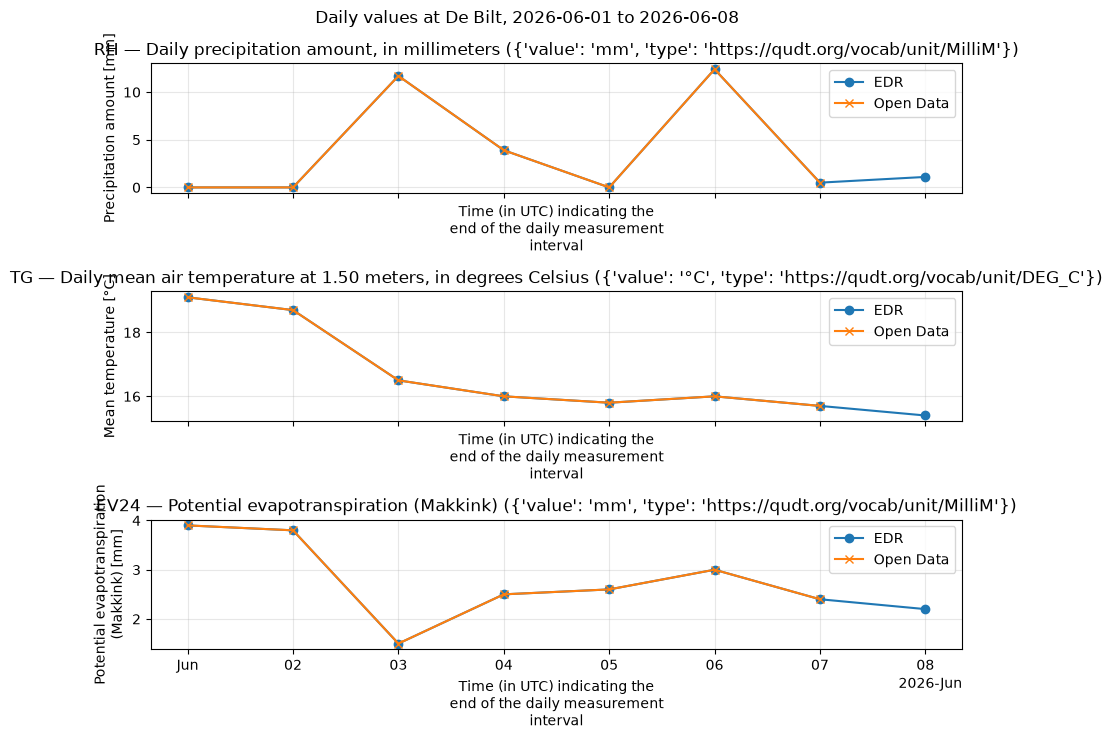

In [8]:
fig, axes = plt.subplots(
    len(PARAMETERS),
    1,
    figsize=(9, 2.5 * len(PARAMETERS)),
    sharex=True,
    layout="tight",
)
for ax, var in zip(axes, PARAMETERS, strict=True):
    # drop singleton dims (x, y, station, coverage) so a 1D time series remains
    da = ts[var].squeeze(drop=True)
    for d in list(da.dims):
        if d != "time" and da.sizes[d] > 1:
            da = da.isel({d: 0})
    da.plot(ax=ax, marker="o", label="EDR")
    das = ds.sel(station=de_bilt_id)[var]  # WSI, e.g. '0-20000-0-06260'
    das.squeeze(drop=True).plot(ax=ax, marker="x", color="C1", label="Open Data")
    ax.legend()
    ax.set_title(
        f"{var} — {da.attrs.get('long_name', var)} ({da.attrs.get('units', '?')})"
    )
    ax.grid(alpha=0.3)
fig.suptitle(f"Daily values at De Bilt, {START.date()} to {END.date()}")

### Method 2: nearest station to coordinates

`/locations` returns a GeoJSON FeatureCollection — one feature per station,
with coordinates and metadata (the station id is the feature `id`, e.g. the
WSI `0-20000-0-06260` for De Bilt). `nearest_location()` picks the closest
station client-side (haversine over `/locations`) and always answers.
`position(..., coords=...)` is the server-side alternative: it matches the
nearest station too, but only within a tolerance and 404s ("no stations")
when nothing is close — caught and printed below for comparison.

In [9]:
locations = client.edr.locations(COLLECTION)
features = locations.get("features", [])
print(f"{len(features)} measurement locations; first 3:")
for feat in features[:3]:
    props = feat.get("properties", {})
    name = props.get("name") or props.get("label")
    print(f"  id={feat.get('id')}: {name} at {feat['geometry']['coordinates']}")

nearest = client.edr.nearest_location(COLLECTION, coords=STATION_COORDS)
de_bilt_id = str(nearest["id"])
print(
    f"Nearest to {STATION_COORDS}: {nearest['name']} (id={de_bilt_id}, "
    f"{nearest['distance_km']:.2f} km)"
)

77 measurement locations; first 3:
  id=0-20000-0-06201: D15-FA-1 at [2.9358, 54.3256]
  id=0-20000-0-06203: P11-B at [3.3417, 52.36]
  id=0-20000-0-06204: K14-FA-1C at [3.6278, 53.2694]
Nearest to (5.18, 52.1): De Bilt (id=0-20000-0-06260, 0.12 km)


In [10]:
ts

<xarray.Dataset> Size: 328B
Dimensions:  (station: 1, time: 8)
Coordinates:
  * station  (station) <U14 56B '5.1797,52.0989'
    lon      (station) float64 8B 5.18
    lat      (station) float64 8B 52.1
  * time     (time) datetime64[us, UTC] 64B 2026-06-01 00:00:00+00:00 ... 202...
Data variables:
    EV24     (station, time) float64 64B 3.9 3.8 1.5 2.5 2.6 3.0 2.4 2.2
    RH       (station, time) float64 64B 0.0 0.0 11.7 3.9 0.0 12.4 0.5 1.1
    TG       (station, time) float64 64B 19.1 18.7 16.5 16.0 15.8 16.0 15.7 15.4

In [11]:
from knmidata import KNMIHTTPError

try:
    ts_position = client.edr.get_position(
        COLLECTION,
        coords=STATION_COORDS,
        start_time=START,
        end_time=END,
        parameters=PARAMETERS,
    )
    print("Position query (server-side nearest):")
    print(ts_position)
except KNMIHTTPError as err:
    # /position does server-side nearest matching within a tolerance; for this
    # station collection a point query can 404 — use method 2 instead.
    print(f"get_position -> HTTP {err.status_code}: {err}")

get_position -> HTTP 404: KNMI API request to https://api.dataplatform.knmi.nl/edr/v1/collections/daily-in-situ-meteorological-observations/position failed with HTTP 404. Response: The query returned no stations


### Method 3: area — all stations in a bounding box

`area` takes a bbox and returns every station inside it (a CoverageCollection
of per-station coverages). `knmidata` merges them along a `station` dimension
whose coordinate values are the station ids (WSI, e.g. '0-20000-0-06260') with
`lon`/`lat` coordinates, so you can always tell which entry belongs to which
station: `area["TG"].sel(station="0-20000-0-06260")`.

In [12]:
area = client.edr.get_area(
    COLLECTION,
    bbox=NL_BBOX,
    start_time=START,
    end_time=END,
    parameters=PARAMETERS,
)
print("All stations within the NL bounding box:")
print(area)

All stations within the NL bounding box:
<xarray.Dataset> Size: 10kB
Dimensions:  (station: 39, time: 8)
Coordinates:
  * station  (station) <U14 2kB '4.4364,52.1397' ... '6.0561,51.4869'
    lon      (station) float64 312B 4.436 4.781 4.79 4.921 ... 4.042 3.804 6.056
    lat      (station) float64 312B 52.14 52.93 52.32 ... 52.32 52.68 51.49
  * time     (time) datetime64[us, UTC] 64B 2026-06-01 00:00:00+00:00 ... 202...
Data variables:
    EV24     (station, time) float64 2kB 4.1 4.3 1.9 2.4 2.8 ... 2.2 2.0 2.6 2.1
    RH       (station, time) float64 2kB 0.0 0.0 13.1 2.3 ... 3.5 18.0 0.5 0.0
    TG       (station, time) float64 2kB 17.4 17.2 16.3 15.8 ... 14.7 15.6 15.1


## Open Data vs EDR — what did we just see?

- **Same dataset, two access patterns.** Open Data gave us whole daily
  *files* (all stations, all variables in the file) assembled along `time`;
  EDR gave us exactly the queried subset (3 variables, 1 station or all
  stations in a bbox, 1 week) as an in-memory dataset.
- **Data volume.** Open Data moves whole files (MBs-GBs each); EDR moves
  only the queried slice (KBs-MBs). EDR is much cheaper for targeted
  questions, but cannot give you data that isn't exposed as a collection.
- **Formats.** Open Data files are NetCDF/HDF5 (this package opens them with
  xarray; GRIB model output would need an extra backend). EDR speaks
  CoverageJSON/GeoJSON, parsed here into xarray.
- **Auth/quota.** Open Data works anonymously within a shared rate limit;
  EDR needs your registered key with a dedicated quota.
- Both paths end in the same place: an `xarray.Dataset` you can analyze,
  plot (as above), or write to disk.

In [13]:
client.close()
print("Client closed.")

Client closed.
